# P1.07 — Population change: natural change and net migration

**Question:** RQ3.1 (how has the population evolved, split into natural change and net migration?). Context for
RQ3.3 and RQ3.6 (demand and prices, `p2_02`, `p2_07`).

Two sources. **National, 1960-2025:** Eurostat's demographic balance (`eurostat_demography`; INE data). **Municipal,
2011-2023:** INE's annual estimates (`ine_population_change`), the only municipal split that exists. Net migration is a
residual of the estimate (it holds statistical adjustments). INE's post-census revision of 2020-2021 (+201,000 persons)
is in the municipal net migration of those years and left out of Eurostat's flows, so it is kept apart here and the
municipal comparison uses 2012-2019 and 2022-2023 (2011 starts from the census).

In [1]:
import pandas as pd

from pthousing.analysis import demography as dem
from pthousing.data import interim
from pthousing.viz import charts, dashboard, style

style.apply_style()
panel = dashboard.load_panel()
euro = interim.read("eurostat_demography")
change = interim.read("ine_population_change")
balance = dem.national_balance(euro)
print(
    f"national {euro['year'].min()}-{euro['year'].max()}; municipal {change['year'].min()}-{change['year'].max()}, {change['muni_code'].nunique()} municipalities"
)

national 1960-2025; municipal 2011-2023, 308 municipalities


## Step 1 — Thirty years nationally
Until 2008 births still exceeded deaths, narrowly. Since 2009 they have not, and the gap widened to about 35,000
a year. Net migration swings far more than natural change: it turned negative with the 2011-2014 crisis, recovered by
2017 and then reached 371,000 in 2022.

In [2]:
periods = [
    (1961, 1973), (1974, 1985), (1986, 1994), (1995, 2000), (2001, 2010),
    (2011, 2014), (2015, 2019), (2020, 2021), (2022, 2025), (1995, 2025),
]  # fmt: skip
summary = dem.period_balance(euro, periods)
style.save_table(summary.round(1).reset_index(names="period"), "p1", "population_change_by_period")
summary[
    [
        "natural_per_year_n",
        "migration_per_year_n",
        "revision_n",
        "total_change_n",
        "migration_share_of_change_pct",
    ]
].round(0)

,natural_per_year_n,migration_per_year_n,revision_n,total_change_n,migration_share_of_change_pct
1961-1973,101864.0,-121848.0,0.0,-259792.0,NaN
1974-1985,64252.0,52500.0,0.0,1401021.0,45.0
1986-1994,18280.0,-20720.0,0.0,-21962.0,NaN
1995-2000,7520.0,46166.0,0.0,322115.0,86.0
2001-2010,2199.0,21996.0,0.0,241947.0,91.0
2011-2014,-17501.0,-26899.0,0.0,-177600.0,NaN
2015-2019,-24277.0,20332.0,0.0,-19726.0,NaN
2020-2021,-42062.0,53585.0,200677.0,223722.0,48.0
2022-2025,-35286.0,241514.0,0.0,824914.0,117.0
1995-2025,-11276.0,50460.0,200677.0,1415372.0,111.0


## Step 2 — Who grows: urban, intermediate and rural municipalities
Rates per 1,000 residents a year in the first year of each window. 2012-2019 is the stagnation, 2022-2023 the surge.

natural_per_1000_year  migration_per_1000_year  \
window  density_class                                                   
2012-19 intermediate                   -1.81                    -0.10   
        rural                          -7.73                    -1.50   
        urban                           0.08                     0.82   
2022-23 intermediate                   -3.01                    31.08   
        rural                          -9.16                    27.61   
        urban                          -1.20                    32.44   

                       population_change_n  
window  density_class                       
2012-19 intermediate                -53080  
        rural                      -165224  
        urban                        34749  
2022-23 intermediate                203955  
        rural                        78836  
        urban                       322439

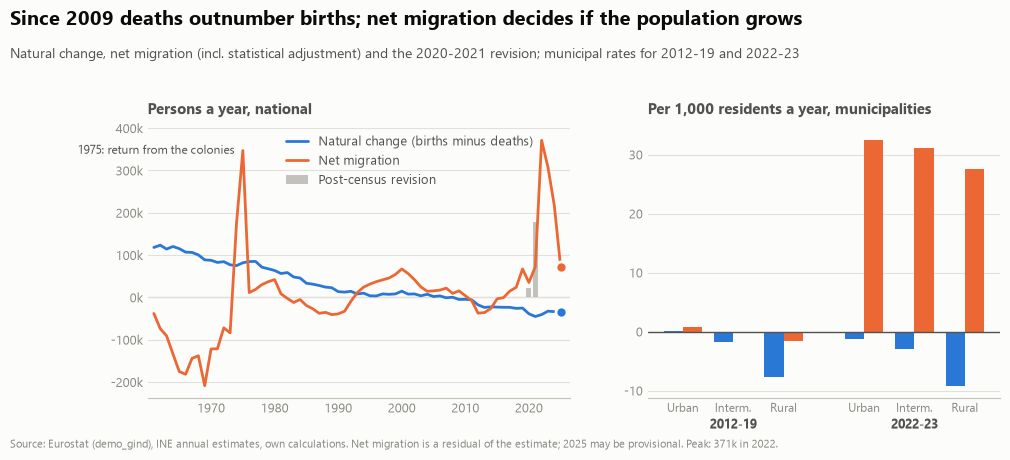

In [3]:
windows = {"2012-19": (2012, 2019), "2022-23": (2022, 2023)}
by_density = {
    label: dem.municipal_balance(change, panel, a, b, by="density_class")
    for label, (a, b) in windows.items()
}
fig = charts.population_components(balance, by_density)
style.save_fig(fig, "p1", "population_components")
tbl = pd.concat(by_density, names=["window", "density_class"]).round(2)
style.save_table(tbl.reset_index(), "p1", "population_components_by_density")
tbl[["natural_per_1000_year", "migration_per_1000_year", "population_change_n"]]

In [4]:
by_coast = pd.concat(
    {
        label: dem.municipal_balance(change, panel, a, b, by="coast_class")
        for label, (a, b) in windows.items()
    },
    names=["window", "coast_class"],
).round(2)
style.save_table(by_coast.reset_index(), "p1", "population_components_by_coast")
by_coast[["natural_per_1000_year", "migration_per_1000_year", "population_change_n"]]

natural_per_1000_year  migration_per_1000_year  \
window  coast_class                                                   
2012-19 coast                        -1.01                     1.21   
        estuary                      -1.34                     3.74   
        inland                       -3.46                    -1.80   
2022-23 coast                        -2.23                    34.90   
        estuary                      -1.71                    40.79   
        inland                       -4.84                    25.01   

                     population_change_n  
window  coast_class                       
2012-19 coast                       7265  
        estuary                    19145  
        inland                   -209965  
2022-23 coast                     318381  
        estuary                    87925  
        inland                    198924

## Step 3 — How municipalities grow
Regimes: a municipality can grow on both counts, grow only because migrants offset natural decline, or shrink
(migrants too few, or leaving). Population is that of the first year of the window.

In [5]:
regimes = pd.concat(
    {
        label: dem.growth_regimes(dem.municipal_balance(change, panel, a, b))
        for label, (a, b) in windows.items()
    },
    names=["window", "regime"],
).round(1)
style.save_table(regimes.reset_index(), "p1", "population_growth_regimes")
regimes

municipalities_n  population_start_n  \
window  regime                                                             
2012-19 decline_both                             186           3959297.0   
        migration_too_small                       60            986908.0   
        migration_offsets_decline                 28           2320583.0   
        migration_loss                            23           2159880.0   
        natural_and_migration_gain                11           1077221.0   
2022-23 migration_offsets_decline                248           8872492.0   
        migration_too_small                       41            247716.0   
        natural_and_migration_gain                14           1778743.0   
        decline_both                               5             30753.0   

                                    population_change_n  \
window  regime                                            
2012-19 decline_both                            -234600   
        migration_too_small                      -31136   
        migration_offsets_decline                 49352   
        migration_loss                            -6140   
        natural_and_migration_gain                38969   
2022-23 migration_offsets_decline                464474   
        migration_too_small                       -2236   
        natural_and_migration_gain               143875   
        decline_both                               -883   

                                    share_of_municipalities_pct  
window  regime                                                   
2012-19 decline_both                                       60.4  
        migration_too_small                                19.5  
        migration_offsets_decline                           9.1  
        migration_loss                                      7.5  
        natural_and_migration_gain                          3.6  
2022-23 migration_offsets_decline                          80.5  
        migration_too_small                                13.3  
        natural_and_migration_gain                          4.5  
        decline_both                                        1.6

## Key numbers

In [6]:
s = summary
r = regimes
print(
    f"1995-2025: natural change {s.loc['1995-2025', 'natural_change_n']:,.0f}, net migration {s.loc['1995-2025', 'net_migration_n']:,.0f}, "
    f"revision {s.loc['1995-2025', 'revision_n']:,.0f}, total {s.loc['1995-2025', 'total_change_n']:,.0f}"
)
print(
    f"deaths above births every year since {int(balance.index[balance['natural_change_n'] >= 0].max()) + 1}; "
    f"2025 natural {balance.loc[2025, 'natural_change_n']:,.0f}, net migration {balance.loc[2025, 'net_migration_n']:,.0f}; "
    f"peak migration {balance['net_migration_n'].max():,.0f} ({int(balance['net_migration_n'].idxmax())})"
)
for label in windows:
    print(label, r.loc[label][["municipalities_n", "share_of_municipalities_pct"]].to_dict("index"))

1995-2025: natural change -349,552, net migration 1,564,247, revision 200,677, total 1,415,372
deaths above births every year since 2009; 2025 natural -34,053, net migration 70,862; peak migration 371,277 (2022)
2012-19 {'decline_both': {'municipalities_n': 186, 'share_of_municipalities_pct': 60.4}, 'migration_too_small': {'municipalities_n': 60, 'share_of_municipalities_pct': 19.5}, 'migration_offsets_decline': {'municipalities_n': 28, 'share_of_municipalities_pct': 9.1}, 'migration_loss': {'municipalities_n': 23, 'share_of_municipalities_pct': 7.5}, 'natural_and_migration_gain': {'municipalities_n': 11, 'share_of_municipalities_pct': 3.6}}
2022-23 {'migration_offsets_decline': {'municipalities_n': 248, 'share_of_municipalities_pct': 80.5}, 'migration_too_small': {'municipalities_n': 41, 'share_of_municipalities_pct': 13.3}, 'natural_and_migration_gain': {'municipalities_n': 14, 'share_of_municipalities_pct': 4.5}, 'decline_both': {'municipalities_n': 5, 'share_of_municipalities_pct':